# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [6]:
# Import necessary libraries 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shutil

shutil.move("/listings.csv.gz", "/content/listings.csv.gz")


'/content/listings.csv.gz'

In [7]:
# Load your uploaded file (path "/content/listings.csv.gz") 🔧
df = pd.read_csv("/content/listings.csv.gz")
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,28871,https://www.airbnb.com/rooms/28871,20260916052246,2026-09-17,NaN,Comfortable double room,Basic bedroom in the center of Amsterdam.,NaN,https://a0.muscache.com/pictures/160889/362340...,124245,...,4.94,4.93,4.83,0363 607B EA74 0BD8 2F6F,NaN,2,0,2,0,4.16
1,29051,https://www.airbnb.com/rooms/29051,20260916052246,2026-09-17,previous scrape,Comfortable single / double room,This room can also be rented as a single or a ...,NaN,https://a0.muscache.com/pictures/162009/bd6be2...,124245,...,4.93,4.88,4.79,0363 607B EA74 0BD8 2F6F,NaN,2,0,2,0,4.92
2,44391,https://www.airbnb.com/rooms/44391,20260916052246,2026-09-17,previous scrape,Quiet 2-bedroom Amsterdam city centre apartment,Guests greatly appreciate the unique location ...,NaN,https://a0.muscache.com/pictures/97741545/3900...,194779,...,4.90,4.68,4.50,0363 E76E F06A C1DD 172C,NaN,1,1,0,0,0.22
3,48373,https://www.airbnb.com/rooms/48373,20260916052246,2026-09-17,previous scrape,Cozy family home in Amsterdam South,Charming modern apartment in the quiet and gre...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,220434,...,5.00,4.60,5.00,0363 4A2B A6AD 0196 F684,NaN,1,1,0,0,0.13
4,49552,https://www.airbnb.com/rooms/49552,20260916052246,2026-09-17,NaN,Multatuli Luxury Guest Suite in top location,Stylish & spacious 60m2 guest suite in Amsterd...,NaN,https://a0.muscache.com/pictures/a6d6d2ee-3196...,225987,...,4.97,4.98,4.79,0363 576A D827 5085 6B83,NaN,1,1,0,0,3.45


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

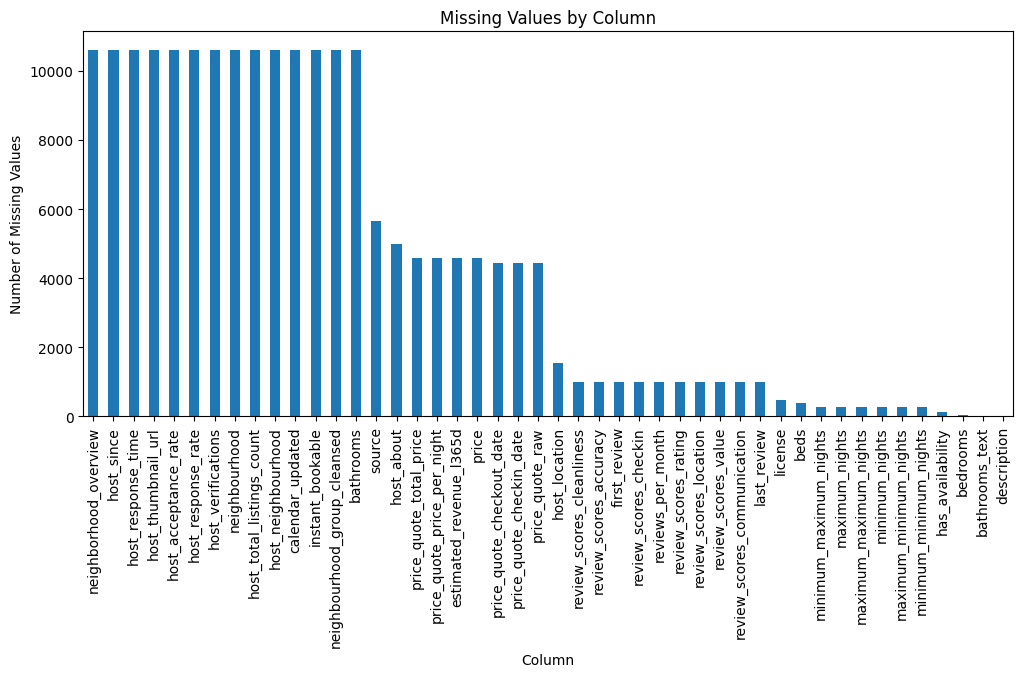

In [8]:
# Add code here 🔧
df.isnull().sum().sort_values(ascending=False)
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]

missing.plot(kind="bar", figsize=(12, 5))
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. There are around 14 columns that have over 10k missing values, but for now, I'll say the top 3 are neighborhood_overview, host-since, and host_response_time.

2. I think those 14 columns with over 10k midssing will create the most issues because the holes are so big that it will misrepresent the data.

3. I think the columns including and past license are good to safely ignore or drop with how minature the missing data is.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [10]:
# Add code here 🔧
df = df.drop(columns=["neighborhood_overview", "host_since"])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10612 entries, 0 to 10611
Data columns (total 85 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            10612 non-null  int64  
 1   listing_url                                   10612 non-null  object 
 2   scrape_id                                     10612 non-null  int64  
 3   last_scraped                                  10612 non-null  object 
 4   source                                        4972 non-null   object 
 5   name                                          10612 non-null  object 
 6   description                                   10608 non-null  object 
 7   picture_url                                   10612 non-null  object 
 8   host_id                                       10612 non-null  int64  
 9   host_url                                      10612 non-null 

### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I chose to drop neighborhood_overview and host_since.

2. neighborhood_overview is descriptive text, which is difficult to directly analyze, and I thought host_since would be better replaced with host reviews.

3. neighborhood_overview would have been harder to analyze and require additional steps while missing values in host_since could skew the range, median, and average of how long a hosts have been on Airbnb.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [14]:
# Your code for converting column data types 🔧
# Fill missing bed counts with the median
df["beds"] = df["beds"].fillna(df["beds"].median())

# Flag listings without a recorded last review
df["last_review_missing"] = df["last_review"].isna()

### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned the beds and last_review columns.

2. For beds, I filled the missing values with the median because there weren't a ton of missing values. For last_review, I created a flag to identify listings with missing review dates because it appeared as if there were 500 missing dates.

3. Replacing the bed count with a median isn't accurate. For last_review, leaving dates missing doesn't explain how recent the reviews were received. This could cause struggle in identifying an active or inactive listing.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [20]:
# Clean or adjust your dataset 🔧
# Convert values to strings, remove dollar signs, and convert to numbers
df["price"] = pd.to_numeric(
    df["price"].astype(str).str.replace("$", "", regex=False),
    errors="coerce"
)

# Check the data type
print(df["price"].dtype)


float64


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed the price column.

2. I convervted price values to strings. got rid of the dollar signs, and converted the values into numeric data.

3. Converting prices to numeric data allows me to calculate summary statistics, which makes data much more useful for analyzation.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [26]:
# Add code here 🔧
df.duplicated().sum()


np.int64(0)

### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. I did not find duplicates.

2. I would decide what to keep or drop depending on if there were repeated listing IDs and exact duplicate rows, or else, I would fear losing useful information.

3. Duplicates are risky for Airbnb teams because it can confuse customers if they see the same listing appear more than once.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [30]:
# export csv here 🔧
df.to_csv("cleaned_airbnb_data_6.csv", index=False)
df.to_csv("/content/cleaned_airbnb_data_6.csv", index=False)

In [28]:
print("Dataset shape:", df.shape)
print("File saved successfully!")

Dataset shape: (10612, 86)
File saved successfully!


In [29]:
import os

print(os.getcwd())
print(os.path.exists("cleaned_airbnb_data_6.csv"))

/content
True


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __  The most challenging sections are the coding for me as it's a lot to memorize the meaning of each unique code.
2. __  I fixed the price column as it was stored as a text with the dollar symbol. Removing the dollar sign and converting the values to numeric data was important to perform calculations and compare listing prices more correctly.
3. __  A business team would benefit from this data because they can price listings at prices that consumers will actually pay without leaving money on the table.
4. __  I would explore how prices vary by the neighborhood, type of room, and review scores to identify patterns.
5. __  This aligns with my customized learning outcome because it allows me to practice and strengthen my analytical skills, which was a personal goal of mine. This will help me to be come a better candidate in the OSC field.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"